In [1]:
import numpy as np
import matplotlib.pyplot as plt


# Add files up one level to the path
import sys
sys.path.append("../..")

from regparam_selection import dp_cubic as dp_cubic2

from scipy.misc import derivative

import jlinops

In [2]:
# # Generate random problem
# n = 100
# m = 60
# k = 75

# np.random.seed(0)
# A = np.random.normal(size=(m,n))
# L = np.random.normal(size=(k,n))
# xtrue = np.random.normal(size=n)
# btrue = _A @ xtrue
# noise_sigma = 0.01
# b = btrue + noise_sigma*np.random.normal(size=len(btrue))

# # # whiten variables
# # A = (1.0/noise_sigma)*A
# # b = (1.0/noise_sigma)*b

In [4]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()[::20]
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.01
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=3, mode="reflect")
A = jlinops.black_box_to_dense(A)
#A = jlinops.IdentityOperator((n,n))
b = (A @ ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

L, _ = jlinops.first_order_derivative_1d(n, boundary="none")
L = L.toarray()

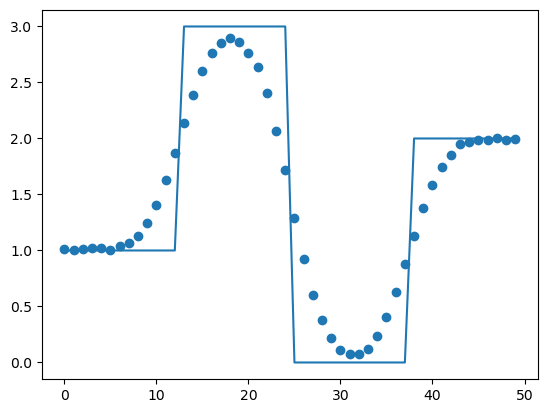

In [5]:
plt.plot(grid, ground_truth)
plt.scatter(grid, b)
plt.show()

In [25]:
def dp_cubic(A, L, b, noise_var, eta=1.0, maxiter=25, beta0=None, tol=1e-5, rtol=1e-5, atol=1e-10, early_stopping=True, shift=0.0, m=None, warmstarting=True):
    """Implements an efficient cubically-convergent root-finder for finding a 
    regularization parameter satisfying the discrepancy principle, for a problem
    of the form

        argmin_x (1.0/noise_var)*|| A x - b ||_2^2 + lambda*|| L x ||_2^2
        
    Each iteration requires the solution of 3 least-squares problems. We assume 
    that A and L are passed as dense matrices. The method is guaranteed to converge 
    under weak assumptions.

    The optimization is done over beta in lambda = 1/beta, instead of lambda itself.
    This guarantees monotonicity/convexity properties of the objective.
    """

    # Whiten the variables
    A = (1.0/np.sqrt(noise_var))*A
    b = (1.0/np.sqrt(noise_var))*b

    # Misc
    Atb = A.T @ b
    if m is not None:
        pass
    else:
        m = len(b)

    if (beta0 is None) or (not warmstarting):
        # Initialize at beta = 0, use analytic formulas for phi and its derivatives
        beta = 0.0
        phi = (np.linalg.norm(b)**2) - (eta**2)*m + shift
        tmp, _, _, _ = np.linalg.lstsq(L.T, Atb, rcond=None)
        phi_prime = -2*(np.linalg.norm(tmp)**2)
        tmp2, _, _, _ = np.linalg.lstsq(L, tmp, rcond=None)
        phi_prime_prime = 2*(np.linalg.norm(tmp2)**2)
    else:
        # Otherwise begin the iteration at the provided beta0
        beta = beta0

        ### Update phi and derivatives
        xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
        Axbeta = A @ xbeta
        Lxbeta = L @ xbeta
        phi = (np.linalg.norm(Axbeta - b)**2) - (eta**2)*m + shift

        # phi prime
        term1 = - (2/(beta**2))*(np.linalg.norm(Lxbeta)**2)
        QinvLtLxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ np.zeros(A.shape[0]),  np.sqrt(beta)*Lxbeta  ]) , rcond=None  )
        #term2 = (2/(beta**2))*np.dot( QinvLtLxbeta, A.T @ Axbeta  )
        AtAxbeta= A.T @ (Axbeta)
        term2 = (2/(beta**2))*np.dot(QinvLtLxbeta, AtAxbeta )
        phi_prime = term1 + term2
        
        # phi prime prime
        term1 = -(2/(beta**4))*np.dot( QinvLtLxbeta, L.T @ Lxbeta )
        AtAQinvLtLxbeta = A.T @ (A @ QinvLtLxbeta)
        term2 = (2/(beta**4))*np.dot(QinvLtLxbeta, AtAQinvLtLxbeta )
        QinvAtAxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ Axbeta, np.zeros(L.shape[0]) ]) , rcond=None  )
        term3 =  (4/(beta**4))*np.dot( L @ QinvAtAxbeta, L @ QinvLtLxbeta )
        term4 = -(2/(beta**4))*np.dot( L @ xbeta, L @ QinvLtLxbeta )
        term5 = -(4/(beta**3))*np.dot(QinvAtAxbeta, L.T @ Lxbeta)
        term6 = +(4/(beta**3))*np.dot(Lxbeta, Lxbeta)
        phi_prime_prime = term1 + term2 + term3 + term4 + term5 + term6

    # Begin the iteration
    beta_hist = [beta]
    phi_hist = [phi]
    n_iters = 0
    for j in range(maxiter):

        # Convergence criteria based on relative change in root
        if j < 2:
            pass
        else:
            if early_stopping:

                if ((beta_hist[-1] - beta_hist[-2])/beta_hist[-2]) < rtol:
                    break

                if np.abs(phi) < atol:
                    break

        ### Take step
        mu = beta + phi_prime/(2*phi_prime_prime)
        alpha = 2*phi_prime*np.sqrt(beta - mu)
        gamma = phi - alpha*np.sqrt(beta - mu)
        beta = mu + ((gamma/alpha)**2)
        #print(beta)
        beta_hist.append(beta)

        ### Update phi and derivatives
        xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
        Axbeta = A @ xbeta
        Lxbeta = L @ xbeta
        phi = (np.linalg.norm(Axbeta - b)**2) - (eta**2)*m + shift
        phi_hist.append(phi)

        # phi prime
        term1 = - (2/(beta**2))*(np.linalg.norm(Lxbeta)**2)
        QinvLtLxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ np.zeros(A.shape[0]),  np.sqrt(beta)*Lxbeta  ]) , rcond=None  )
        #term2 = (2/(beta**2))*np.dot( QinvLtLxbeta, A.T @ Axbeta  )
        AtAxbeta = A.T @ (Axbeta)
        term2 = (2/(beta**2))*np.dot(QinvLtLxbeta, AtAxbeta )
        phi_prime = term1 + term2
        
        # phi prime prime
        term1 = -(2/(beta**4))*np.dot( QinvLtLxbeta, L.T @ Lxbeta )
        AtAQinvLtLxbeta = A.T @ (A @ QinvLtLxbeta)
        term2 = (2/(beta**4))*np.dot(QinvLtLxbeta, AtAQinvLtLxbeta )
        QinvAtAxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ Axbeta, np.zeros(L.shape[0]) ]), rcond=None  )
        term3 =  (4/(beta**4))*np.dot( L @ QinvAtAxbeta, L @ QinvLtLxbeta )
        term4 = -(2/(beta**4))*np.dot( L @ xbeta, L @ QinvLtLxbeta )
        term5 = -(4/(beta**3))*np.dot(QinvAtAxbeta, L.T @ Lxbeta)
        term6 = +(4/(beta**3))*np.dot(Lxbeta, Lxbeta)
        phi_prime_prime = term1 + term2 + term3 + term4 + term5 + term6

        # Increase counter
        n_iters += 1

  
    data = {
        "beta": beta,
        "lambda": 1.0/beta,
        "beta_hist": np.asarray(beta_hist),
        "phi_hist": np.asarray(phi_hist),
        "n_iters": n_iters,
    }
    
    return data


In [46]:
def dp_cubic_val(A, L, b, noise_var, eta=1.0, maxiter=25, beta0=None, rtol=1e-5, atol=1e-10, order=5, dx=1e-6, early_stopping=True):
    """Implements an efficient cubically-convergent root-finder for finding a 
    regularization parameter satisfying the discrepancy principle, for a problem
    of the form

        argmin_x (1.0/noise_var)*|| A x - b ||_2^2 + lambda*|| L x ||_2^2
        
    Each iteration requires the solution of 3 least-squares problems. We assume 
    that A and L are passed as dense matrices. The method is guaranteed to converge 
    under weak assumptions.

    The optimization is done over beta in lambda = 1/beta, instead of lambda itself.
    This guarantees convexity of the objective.

    rtol: controls stopping criterion based on relative change in the solution.
    atol: controls stopping criterion based on the absolute deviation of objective from zero.
    """

    # Whiten the variables
    A = (1.0/np.sqrt(noise_var))*A
    b = (1.0/np.sqrt(noise_var))*b

    # Misc
    Atb = A.T @ b

    # Build func
    def _phi(beta):
        xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
        Axbeta = A @ xbeta
        return (np.linalg.norm(Axbeta - b)**2) - (eta**2)*len(b)

    if beta0 is None:
        # Initialize at beta = 0, use analytic formulas for phi and its derivatives
        beta = 0.0
        phi = (np.linalg.norm(b)**2) - (eta**2)*len(b)
        tmp, _, _, _ = np.linalg.lstsq(L.T, Atb)
        phi_prime = -2*(np.linalg.norm(tmp)**2)
        tmp2, _, _, _ = np.linalg.lstsq(L, tmp)
        phi_prime_prime = 2*(np.linalg.norm(tmp2)**2)
    else:
        # Otherwise begin the iteration at the provided beta0
        beta = beta0

        ### Update phi and derivatives
        xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
        Axbeta = A @ xbeta
        Lxbeta = L @ xbeta
        phi = _phi(beta)

        # phi prime
        phi_prime = derivative(_phi, x0=beta, order=order, dx=dx, n=1)
        
        # phi prime prime
        phi_prime_prime = derivative(_phi, x0=beta, order=order, dx=dx, n=2)

    # Begin the iteration
    beta_hist = [beta]
    phi_hist = [phi]
    n_iters = 0
    for j in range(maxiter):

        # Convergence criteria based on relative change in root
        if j < 2:
            pass
        else:
            if early_stopping:

                if ((beta_hist[-1] - beta_hist[-2])/beta_hist[-2]) < rtol:
                    break

                if np.abs(phi) < atol:
                    break

        ### Take step
        mu = beta + phi_prime/(2*phi_prime_prime)
        alpha = 2*phi_prime*np.sqrt(beta - mu)
        gamma = phi - alpha*np.sqrt(beta - mu)
        beta = mu + ((gamma/alpha)**2)
        beta_hist.append(beta)

        ### Update phi and derivatives
        xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
        Axbeta = A @ xbeta
        Lxbeta = L @ xbeta
        phi = _phi(beta)
        phi_hist.append(phi)

        # phi prime
        phi_prime = derivative(_phi, x0=beta, order=order, dx=dx, n=1)
        
        # phi prime prime
        phi_prime_prime = derivative(_phi, x0=beta, order=order, dx=dx, n=2)

        # Increase counter
        n_iters += 1

    data = {
        "beta": beta,
        "lambda": 1.0/beta,
        "beta_hist": np.asarray(beta_hist),
        "phi_hist": np.asarray(phi_hist),
        "n_iters": n_iters,
    }
    
    return data


In [32]:
data = dp_cubic(A, L, b, noise_stdev**2, eta=1.01, maxiter=35, beta0=None, rtol=1e-3, early_stopping=True)

In [38]:
datav = dp_cubic_val(A, L, b, noise_stdev**2, eta=1.01, maxiter=35, beta0=None, rtol=1e-3, early_stopping=True)

/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_59676/3904188021.py:36: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  tmp, _, _, _ = np.linalg.lstsq(L.T, Atb)
/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_59676/3904188021.py:38: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  tmp2, _, _, _ = np.linalg.lstsq(L, tmp)
/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_59676/3904188021.py:89: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely remov

In [39]:
data["phi_hist"]

array([1.40494097e+06, 5.57092721e+04, 1.67281514e+04, 4.95598513e+03,
       1.55126312e+03, 5.66761246e+02, 2.33081388e+02, 7.25491684e+01,
       1.98778395e+01, 3.09992998e+00, 5.86228283e-02, 6.24818490e-07,
       2.27373675e-13])

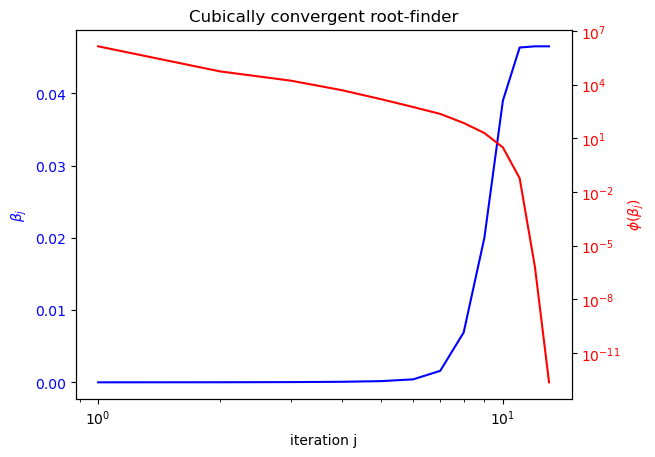

In [40]:
# Create a figure and a set of subplots
fig, ax1 = plt.subplots()

iters = np.arange(1, data["n_iters"]+2)

# Plot the first curve using the left y-axis
ax1.plot(iters, data["beta_hist"], 'b-', label='sin(x)')
ax1.set_xlabel('iteration j')
ax1.set_ylabel('$\\beta_j$', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_xscale("log")

# Create a second y-axis sharing the same x-axis
ax2 = ax1.twinx()
ax2.plot(iters, data["phi_hist"], 'r-', label='exp(x / 3)')
ax2.set_ylabel('$\\phi(\\beta_j)$', color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.set_yscale("log")


# Title and show plot
plt.title("Cubically convergent root-finder")
plt.show()

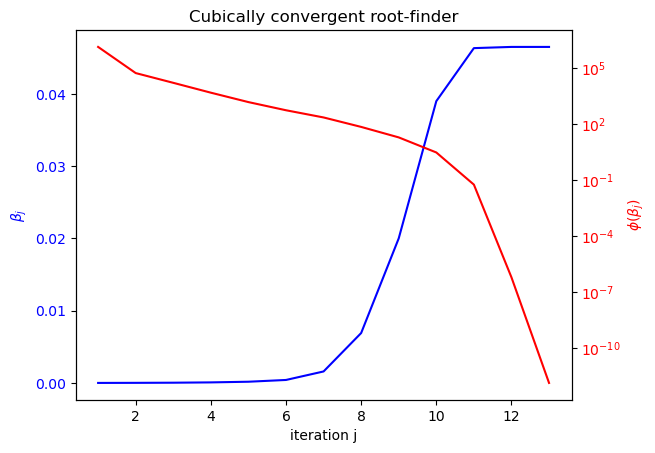

In [43]:
# Create a figure and a set of subplots
fig, ax1 = plt.subplots()

iters = np.arange(1, datav["n_iters"]+2)

# Plot the first curve using the left y-axis
ax1.plot(iters, datav["beta_hist"], 'b-', label='sin(x)')
ax1.set_xlabel('iteration j')
ax1.set_ylabel('$\\beta_j$', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Create a second y-axis sharing the same x-axis
ax2 = ax1.twinx()
ax2.plot(iters, datav["phi_hist"], 'r-', label='exp(x / 3)')
ax2.set_ylabel('$\\phi(\\beta_j)$', color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.set_yscale("log")


# Title and show plot
plt.title("Cubically convergent root-finder")
plt.show()

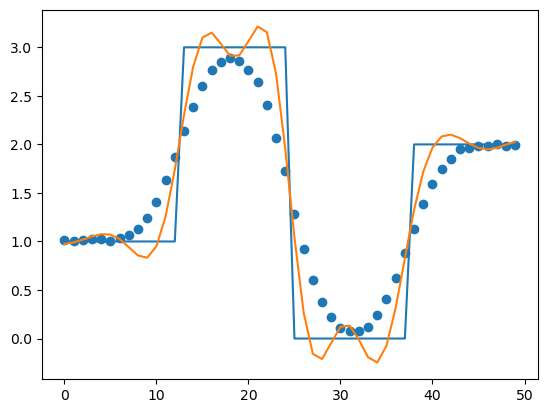

In [45]:
sol = np.linalg.solve((1.0/noise_var)*(A.T @ A ) + data["lambda"]*( L.T@ L ), (1.0/noise_var)*A.T @ b )
plt.plot(grid, ground_truth)
plt.scatter(grid, b)
plt.plot( grid, sol )
plt.show()

In [37]:
np.linalg.norm( (A @ sol) - b )**2

0.005219575796362587

In [38]:
noise_var*len(sol)*(1.02**2)

0.005202

In [29]:
data = dp_cubic2( (1.0/noise_stdev)*A, L, (1.0/noise_stdev)*b, 1.0, eta=1.02, maxiter=1000, beta0=None, tol=1e-3)

1.049760376985176e-05
0.033171133452523496
0.03390722999824816
0.03460534633848793
0.03526558881065789
0.03588836080598901
0.03647432478703731
0.037024364204093954
0.037539546336348324
0.03802108687349712
0.038470316849918196
0.038888652355396174
0.03927756727962741
0.03963856920557826
0.03997317845031806
0.04028291016056745
0.040569259302067825
0.04083368833443053
0.04107761733335588
0.04130241630697237
0.04150939944951361
0.04169982108092361
0.04187487303280191
0.042035683257344865
0.04218331545489987
0.0423187695360767
0.04244298275502169
0.04255683137069083
0.042661132712206284
0.042756647542300824
0.04284408262923489
0.0429240934523073
0.04299728697917919
0.043064224464706646
0.043125424230954265
0.04318136439662948
0.04323248553146282
0.04327919321720732
0.043321860502063055


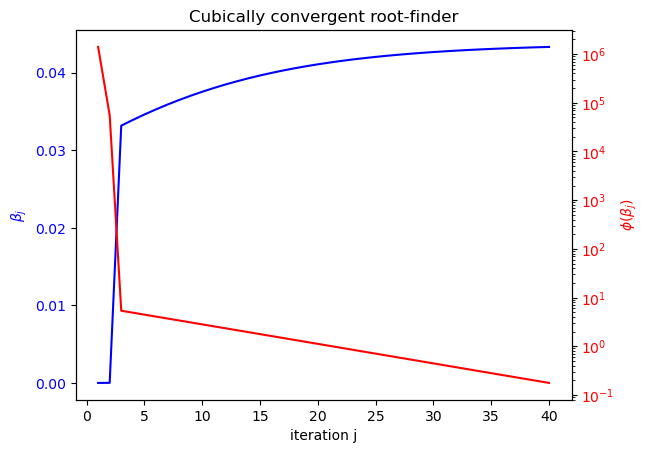

In [30]:
# Create a figure and a set of subplots
fig, ax1 = plt.subplots()

iters = np.arange(1, data["n_iters"]+2)

# Plot the first curve using the left y-axis
ax1.plot(iters, data["beta_hist"], 'b-', label='sin(x)')
ax1.set_xlabel('iteration j')
ax1.set_ylabel('$\\beta_j$', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Create a second y-axis sharing the same x-axis
ax2 = ax1.twinx()
ax2.plot(iters, data["phi_hist"], 'r-', label='exp(x / 3)')
ax2.set_ylabel('$\\phi(\\beta_j)$', color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.set_yscale("log")


# Title and show plot
plt.title("Cubically convergent root-finder")
plt.show()

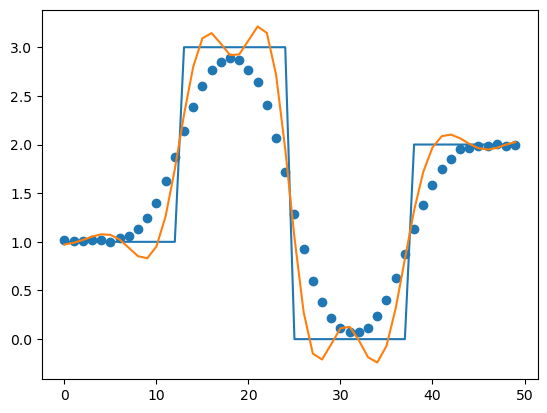

In [31]:
sol = np.linalg.solve((1.0/noise_var)*(A.T @ A ) + data["lambda"]*( L.T@ L ), (1.0/noise_var)*A.T @ b )
plt.plot(grid, ground_truth)
plt.scatter(grid, b)
plt.plot( grid, sol )
plt.show()

# Check derivatives

In [209]:
# Build func
eta = 1.01

def _phi(beta):
    xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
    Axbeta = A @ xbeta
    return (np.linalg.norm(Axbeta - b)**2) - (eta**2)*len(b)

def _phi_prime(beta):
    xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
    Axbeta = A @ xbeta
    Lxbeta = L @ xbeta

    # phi prime
    term1 = - (2/(beta**2))*(np.linalg.norm(Lxbeta)**2)
    #QinvLtLxbeta = np.linalg.solve(A.T @ A + (1.0/beta)*L.T @ L, L.T @ L @ xbeta )
    QinvLtLxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ np.zeros(A.shape[0]),  np.sqrt(beta)*Lxbeta  ]) , rcond=None  )
    #term2 = (2/(beta**2))*np.dot( QinvLtLxbeta, A.T @ Axbeta  )
    AtAxbeta= A.T @ (A @ xbeta)
    term2 = (2/(beta**2))*np.dot(QinvLtLxbeta, AtAxbeta)
    phi_prime = term1 + term2

    # term1 = - (2/(beta**2))*(np.linalg.norm(Lxbeta)**2)
    # QinvLtLxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ np.zeros(A.shape[0]),  Lxbeta  ]) , rcond=None  )
    # #term2 = (2/(beta**2))*np.dot( QinvLtLxbeta, A.T @ Axbeta  )
    # AtAQinvLtLxbeta = A.T @ (A @ QinvLtLxbeta)
    # term2 = (2/(beta**2))*np.dot(QinvLtLxbeta, AtAQinvLtLxbeta )
    # phi_prime = 2*(term2 - term1)/(beta**2)


    return phi_prime
        
def _phi_prime_prime(beta):
    xbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ b, np.zeros(L.shape[0]) ]) , rcond=None  )
    Axbeta = A @ xbeta
    Lxbeta = L @ xbeta
    
    # phi prime
    term1 = - (2/(beta**2))*(np.linalg.norm(Lxbeta)**2)
    QinvLtLxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ np.zeros(A.shape[0]),  np.sqrt(beta)*Lxbeta  ]) , rcond=None  )
    #term2 = (2/(beta**2))*np.dot( QinvLtLxbeta, A.T @ Axbeta  )
    AtAQinvLtLxbeta = A.T @ (A @ QinvLtLxbeta)
    term2 = (2/(beta**2))*np.dot(QinvLtLxbeta, AtAQinvLtLxbeta )
    phi_prime = term1 + term2
        
    # phi prime prime
    term1 = -(2/(beta**4))*np.dot( QinvLtLxbeta, L.T @ Lxbeta )
    term2 = (2/(beta**4))*np.dot(QinvLtLxbeta, AtAQinvLtLxbeta )
    QinvAtAxbeta, _, _, _ = np.linalg.lstsq( np.vstack([ A, np.sqrt(1.0/beta)*L ]), np.hstack([ Axbeta, np.zeros(L.shape[0]) ]), rcond=None  )
    term3 =  (4/(beta**4))*np.dot( L @ QinvAtAxbeta, L @ QinvLtLxbeta )
    term4 = -(2/(beta**4))*np.dot( L @ xbeta, L @ QinvLtLxbeta )
    term5 = -(4/(beta**3))*np.dot(QinvAtAxbeta, L.T @ Lxbeta)
    term6 = +(4/(beta**3))*np.dot(Lxbeta, Lxbeta)
    phi_prime_prime = term1 + term2 + term3 + term4 + term5 + term6

    return phi_prime_prime



In [210]:
beta = 1e2
order = 5
dx = 1e-6

print(_phi_prime(beta))
print(derivative(_phi, x0=beta, order=order, dx=dx, n=1))

-5.4503818525494904e-05
-5.4508397795416386e-05


/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_20071/809212860.py:6: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. You may consider using findiff: https://github.com/maroba/findiff or numdifftools: https://github.com/pbrod/numdifftools
  print(derivative(_phi, x0=beta, order=order, dx=dx, n=1))


In [222]:
beta = 1e0
order = 5
dx = 1e-5

print(_phi_prime(beta))
print(derivative(_phi, x0=beta, order=order, dx=dx, n=1))

-0.4577166587010417
-0.4577166586194891


/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_20071/2685565132.py:6: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. You may consider using findiff: https://github.com/maroba/findiff or numdifftools: https://github.com/pbrod/numdifftools
  print(derivative(_phi, x0=beta, order=order, dx=dx, n=1))


In [225]:
beta = 1e-1
order = 9
dx = 1e-5

print(_phi_prime_prime(beta))
print(derivative(_phi, x0=beta, order=order, dx=dx, n=2))

954.6544758444152
954.6564971874004


/var/folders/fn/xbs7g2ln57x3xrdggzf_dzzm0000gr/T/ipykernel_20071/1786858998.py:6: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. You may consider using findiff: https://github.com/maroba/findiff or numdifftools: https://github.com/pbrod/numdifftools
  print(derivative(_phi, x0=beta, order=order, dx=dx, n=2))
